# Ejercicio pandas estadística
Para este ejercicio se ha utilizado [un dataset de un concurso de kaggle](https://www.kaggle.com/nickhould/craft-cans), cuyo reto consiste en predecir el tipo de cerveza en función de sus características (nivel de alcohol, amargura, tamaño...).

# Ejercicio 1
Importa las librerias que consideres

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


## Ejercicio 2
1. Importa el dataset "datasets_beer.csv"
2. Imprime por pantalla los primeros registros.
3. ¿Cuáles son sus columnas?
4. ¿Qué dimensiones tiene el DataFrame?

In [5]:
df_beer = pd.read_csv("data/datasets_beers.csv")

display(df_beer.head())

print("Columnas:", df_beer.columns.tolist())

print("Dimensiones (filas, columnas):", df_beer.shape)

,Unnamed: 0,abv,ibu,id,name,style,brewery_id,ounces
0,0,0.050,NaN,1436,Pub Beer,American Pale Lager,408,12.0
1,1,0.066,NaN,2265,Devil's Cup,American Pale Ale (APA),177,12.0
2,2,0.071,NaN,2264,Rise of the Phoenix,American IPA,177,12.0
3,3,0.090,NaN,2263,Sinister,American Double / Imperial IPA,177,12.0
4,4,0.075,NaN,2262,Sex and Candy,American IPA,177,12.0


Columnas: ['Unnamed: 0', 'abv', 'ibu', 'id', 'name', 'style', 'brewery_id', 'ounces']
Dimensiones (filas, columnas): (2410, 8)


## Ejercicio 3
[Elimina la columna "Unnamed: 0"](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.drop.html)

In [6]:
df_beer = df_beer.drop(columns=["Unnamed: 0"])

## Ejercicio 4
¿Cuántas filas y columnas tiene el dataset?

In [7]:
filas, columnas = df_beer.shape
print(f"El dataset tiene {filas} filas y {columnas} columnas.")

El dataset tiene 2410 filas y 7 columnas.


## Ejercicio 5
¿De qué tipo son los datos?

In [8]:
print(df_beer.dtypes)

abv           float64
ibu           float64
id              int64
name              str
style             str
brewery_id      int64
ounces        float64
dtype: object


## Ejercicio 6
Obtén en un nuevo DataFrame un resumen con las principales estadísticas de las columnas numéricas: mean, max, count, cuartiles...

In [9]:
df_beer.describe()

,abv,ibu,id,brewery_id,ounces
count,2348.000000,1405.000000,2410.000000,2410.000000,2410.000000
mean,0.059773,42.713167,1431.113278,231.749793,13.592241
std,0.013542,25.954066,752.459975,157.685604,2.352204
min,0.001000,4.000000,1.000000,0.000000,8.400000
25%,0.050000,21.000000,808.250000,93.000000,12.000000
50%,0.056000,35.000000,1453.500000,205.000000,12.000000
75%,0.067000,64.000000,2075.750000,366.000000,16.000000
max,0.128000,138.000000,2692.000000,557.000000,32.000000


## Ejercicio 7
¿Cuántas birras hay de cada estilo en este dataset? [Investiga en la documentación de Series](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.Series.html) si puedes hacer un conteo de valores.

In [10]:
conteo_estilos = df_beer['style'].value_counts()
display(conteo_estilos)

style
American IPA                      424
American Pale Ale (APA)           245
American Amber / Red Ale          133
American Blonde Ale               108
American Double / Imperial IPA    105
                                 ... 
American Malt Liquor                1
Grisette                            1
Flanders Oud Bruin                  1
Braggot                             1
Low Alcohol Beer                    1
Name: count, Length: 99, dtype: int64

## Ejercicio 8
1. Imprime por pantalla los registros desde el décimo hasta el vigésimo
2. De esos registros, imprime por pantalla desde la columna `name` a `ounces`, ambas incluidas
3. Quédate con las columnas `abv`, `ibu` y `ounces`, y además quédate sólo con los registros 10 al 20.
4. Convierte el resultado del apartado 3 en un array de `numpy`

In [11]:

registros_10_20 = df_beer.iloc[9:20]


sub_df = df_beer.loc[9:19, 'name':'ounces']
display(sub_df)

sub_cols = df_beer.loc[9:19, ['abv', 'ibu', 'ounces']]

array_numpy = sub_cols.to_numpy()
print(array_numpy)

,name,style,brewery_id,ounces
9,Cone Crusher,American Double / Imperial IPA,177,12.0
10,Sophomoric Saison,Saison / Farmhouse Ale,177,12.0
11,Regional Ring Of Fire,Saison / Farmhouse Ale,177,12.0
12,Garce Selé,Saison / Farmhouse Ale,177,12.0
13,Troll Destroyer,Belgian IPA,177,12.0
14,Bitter Bitch,American Pale Ale (APA),177,12.0
15,Ginja Ninja,Cider,154,12.0
16,Cherried Away,Cider,154,12.0
17,Rhubarbarian,Cider,154,12.0
18,BrightCider,Cider,154,12.0


[[ 0.086    nan 12.   ]
 [ 0.072    nan 12.   ]
 [ 0.073    nan 12.   ]
 [ 0.069    nan 12.   ]
 [ 0.085    nan 12.   ]
 [ 0.061 60.    12.   ]
 [ 0.06     nan 12.   ]
 [ 0.06     nan 12.   ]
 [ 0.06     nan 12.   ]
 [ 0.06     nan 12.   ]
 [ 0.082    nan 12.   ]]


## Ejercicio 9
¿Cuántas onzas pesan todas las birras del dataset?

In [12]:
total_onzas = df_beer['ounces'].sum()
print(f"Total de onzas en el dataset: {total_onzas}")

Total de onzas en el dataset: 32757.3


## Ejercicio 10
El amargor de las cervezas se mide por su nivel de IBUs.
1. ¿Cuál es el amargor medio de las cervezas?
2. ¿El máximo? ¿Y el mínimo?
3. ¿Qué cerveza es la que tiene el amargor máximo? ¿Cuál es la de amargor mínimo?

In [13]:
media_ibu = df_beer['ibu'].mean()
print(f"Amargor medio: {media_ibu:.2f}")


max_ibu = df_beer['ibu'].max()
min_ibu = df_beer['ibu'].min()
print(f"Máximo IBU: {max_ibu}, Mínimo IBU: {min_ibu}")

cerveza_max_ibu = df_beer.loc[df_beer['ibu'].idxmax()]
cerveza_min_ibu = df_beer.loc[df_beer['ibu'].idxmin()]

print("Cerveza con mayor IBU:\n", cerveza_max_ibu[['name', 'style', 'ibu']])
print("\nCerveza con menor IBU:\n", cerveza_min_ibu[['name', 'style', 'ibu']])

Amargor medio: 42.71
Máximo IBU: 138.0, Mínimo IBU: 4.0
Cerveza con mayor IBU:
 name          Bitter Bitch Imperial IPA
style    American Double / Imperial IPA
ibu                               138.0
Name: 147, dtype: object

Cerveza con menor IBU:
 name     Summer Solstice
style          Cream Ale
ibu                  4.0
Name: 106, dtype: object


## Ejercicio 11
No queda muy claro cuánto de dispar, de dispersa, es la medida de IBU. Mediante estadística descriptiva (una o dos métricas, sin gráficas), razona la dispersión de la variable IBU.

In [14]:
std_ibu = df_beer['ibu'].std()
iqr_ibu = df_beer['ibu'].quantile(0.75) - df_beer['ibu'].quantile(0.25)

print(f"Desviación estándar del IBU: {std_ibu:.2f}")
print(f"Rango Intercuartílico (IQR) del IBU: {iqr_ibu:.2f}")

Desviación estándar del IBU: 25.95
Rango Intercuartílico (IQR) del IBU: 43.00


## Ejercicio 12
¿Existe alguna relación lineal entre las variables numéricas del dataset? Intenta pintar este razonamiento mediante un gráfico

,abv,ibu,id,brewery_id,ounces
abv,1.000000,0.670621,0.042811,-0.098632,0.172529
ibu,0.670621,1.000000,0.000485,-0.004875,0.054691
id,0.042811,0.000485,1.000000,-0.504030,0.100843
brewery_id,-0.098632,-0.004875,-0.504030,1.000000,-0.133762
ounces,0.172529,0.054691,0.100843,-0.133762,1.000000


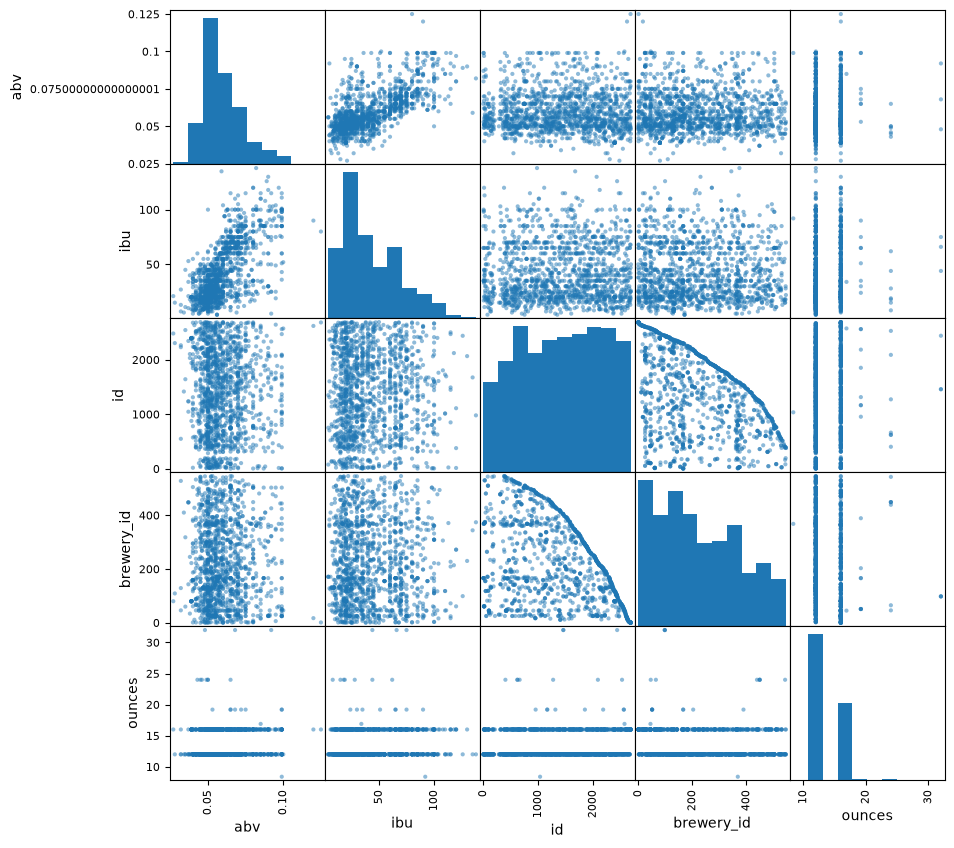

In [15]:
corr_matrix = df_beer.select_dtypes(include='number').corr()
display(corr_matrix)

pd.plotting.scatter_matrix(df_beer.select_dtypes(include='number').dropna(), figsize=(10, 10))
plt.show()

## Ejercicio 13
Representa el nivel de alcohol (columna `abv`) en un histograma. ¿Se trata de una distribución simétrica o asimétrica?

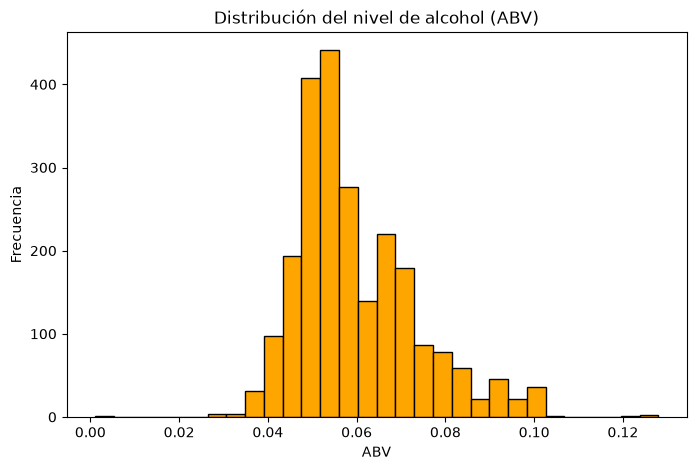

In [16]:
plt.figure(figsize=(8, 5))
plt.hist(df_beer['abv'].dropna(), bins=30, color='orange', edgecolor='black')
plt.title('Distribución del nivel de alcohol (ABV)')
plt.xlabel('ABV')
plt.ylabel('Frecuencia')
plt.show()

## Ejercicio 14
Representa mediante un *boxplot* de `seaborn` la variable `abv`

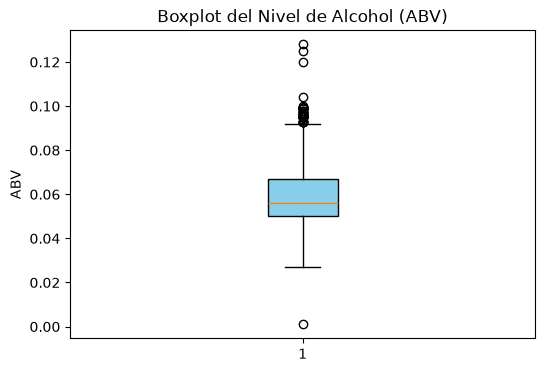

In [17]:
plt.figure(figsize=(6, 4))
plt.boxplot(df_beer['abv'].dropna(), patch_artist=True, boxprops=dict(facecolor='skyblue'))
plt.title('Boxplot del Nivel de Alcohol (ABV)')
plt.ylabel('ABV')
plt.show()

## Ejercicio 15
1. ¿Qué estilos son los que tienen en media más alcohol?
2. ¿Y los estilos que son en media más amargos?

In [18]:
top_alcohol = df_beer.groupby('style')['abv'].mean().sort_values(ascending=False).head(5)
print("Estilos con más alcohol en media:\n", top_alcohol)

top_amargor = df_beer.groupby('style')['ibu'].mean().sort_values(ascending=False).head(5)
print("\nEstilos más amargos en media:\n", top_amargor)

Estilos con más alcohol en media:
 style
English Barleywine        0.107667
Quadrupel (Quad)          0.104000
American Barleywine       0.099000
American Malt Liquor      0.099000
Russian Imperial Stout    0.097636
Name: abv, dtype: float64

Estilos más amargos en media:
 style
American Barleywine                   96.00
American Double / Imperial IPA        93.32
Russian Imperial Stout                86.50
American Double / Imperial Pilsner    85.00
Belgian Strong Dark Ale               72.00
Name: ibu, dtype: float64


## Ejercicio 16
Carga el datasets de cervecerias `datasets_breweries.csv`

In [20]:
df_breweries = pd.read_csv("data/datasets_breweries.csv")

## Ejercicio 17
1. Renombra la columna `Unnamed: 0` como `brewery_id`
2. Renombra también la columna `name` por `brewery_name`. ¿Puedes hacer ambos apartados en una sola sentencia?

In [21]:
df_breweries = df_breweries.rename(columns={
    'Unnamed: 0': 'brewery_id',
    'name': 'brewery_name'
})

## Ejercicio 18
Junta los dos datasets que tienes

In [ ]:
df_merged = pd.merge(df_beer, df_breweries, left_on='brewery_id', right_on='brewery_id', suffixes=('_beer', '_brewery'))

## Ejercicio 19
1. ¿Cuántos estados diferentes hay?
2. ¿Y ciudades diferentes?
3. ¿Cuántas cervecerías hay?

In [ ]:
num_estados = df_merged['state'].nunique()
num_ciudades = df_merged['city'].nunique()
num_cervecerias = df_merged['brewery_name'].nunique()

print(f"Estados diferentes: {num_estados}")
print(f"Ciudades diferentes: {num_ciudades}")
print(f"Cervecerías diferentes: {num_cervecerias}")

## Ejercicio 20
Agrupa por estado y ciudad, la media, mediana y máximo nivel de alcohol

In [ ]:
stats_abv = df_merged.groupby(['state', 'city'])['abv'].agg(['mean', 'median', 'max'])
display(stats_abv)

## Ejercicio 21
¿Cuáles son las cervezas más amargas que se consumen en Indiana, estado = `IN`?

In [ ]:
cervezas_in = df_merged[df_merged['state'].str.strip() == 'IN'].sort_values(by='ibu', ascending=False)
display(cervezas_in[['name_beer', 'brewery_name', 'ibu', 'style']].head(10))

## Ejercicio 22
Obtén una tabla con los principales estadísticos del campo `ibu`,  a nivel ciudad

In [ ]:
stats_ibu_city = df_merged.groupby('city')['ibu'].describe()
display(stats_ibu_city)

## Ejercicio 23
Consigue en un DataFrame de todas las cervezas en cuyas cervecerías al menos haya una cerveza con un `abv` mínimo 0.07.

In [ ]:
cervecerias_ids = df_merged[df_merged['abv'] >= 0.07]['brewery_id'].unique()
df_cervecerias_altas = df_merged[df_merged['brewery_id'].isin(cervecerias_ids)]
display(df_cervecerias_altas[['name_beer', 'brewery_name', 'abv']])

## Ejercicio 24
Teniendo en cuenta la media de amargor de todas las cervezas, obtén una tabla con las cervezas cuyos estados tengan una media de amargor en cerveza por encima de la media

In [ ]:
media_global_ibu = df_merged['ibu'].mean()
media_por_estado = df_merged.groupby('state')['ibu'].mean()
estados_altos_ibu = media_por_estado[media_por_estado > media_global_ibu].index

df_cervecerias_estado_amargo = df_merged[df_merged['state'].isin(estados_altos_ibu)]
display(df_cervecerias_estado_amargo[['name_beer', 'state', 'ibu']].head(10))